# EDA — Tech Challenge

Análisis exploratorio del dataset `s3://data/raw/data.csv`. Todo el análisis se hace **solo sobre el split de train** (el mismo que usa la plataforma) para no tomar decisiones de preprocesado viendo el test.

Figuras, tablas y conclusiones se registran en MLflow (experimento `eda`), es decir, en S3. Las conclusiones de la sección 9 son la base de `features.py`.

In [1]:
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from mlplatform.config import get_settings
from mlplatform.data import digest, features_target, load_dataset, make_split

settings = get_settings()
df = load_dataset()
X, y = features_target(df)
split = make_split(y)
X_tr, y_tr = X.loc[split.train], y.loc[split.train]

num_cols = X_tr.select_dtypes("number").columns.tolist()
cat_cols = [c for c in X_tr.columns if c not in num_cols and c != "Timestamp"]

mlflow.set_tracking_uri(settings.mlflow_tracking_uri)
mlflow.set_experiment("eda")
mlflow.start_run(run_name="eda", tags={"data_digest": digest(df)})
mlflow.log_input(mlflow.data.from_pandas(df, source=settings.data_uri, targets=settings.target, name="raw"), context="eda")
mlflow.log_params({"n_rows": len(df), "n_train": len(X_tr), "seed": settings.seed, "test_size": settings.test_size})


def log_fig(fig, name):
    mlflow.log_figure(fig, f"figures/{name}.png")


def log_table(table, name):
    mlflow.log_table(data=table.reset_index(names="feature"), artifact_file=f"tables/{name}.json")


print(f"dataset {df.shape} | train {X_tr.shape} | numéricas {len(num_cols)} | categóricas {len(cat_cols)}")

2026/10/18 11:17:04 INFO mlflow.tracking.fluent: Experiment with name 'eda' does not exist. Creating a new experiment.


dataset (500, 32) | train (400, 31) | numéricas 20 | categóricas 10


## 1. Calidad de datos

In [2]:
quality = pd.DataFrame({
    "dtype": X_tr.dtypes.astype(str),
    "nulls": X_tr.isna().sum(),
    "null_frac": X_tr.isna().mean().round(3),
    "n_unique": X_tr.nunique(),
})
log_table(quality, "quality")
print("filas duplicadas:", X_tr.duplicated().sum())
print("nulos por fila:", X_tr.isna().sum(axis=1).value_counts().sort_index().to_dict())
quality.sort_values("null_frac", ascending=False).head(8)

filas duplicadas: 0
nulos por fila: {0: 28, 1: 273, 2: 91, 3: 8}


,dtype,nulls,null_frac,n_unique
F17,float64,361,0.902,39
F1,str,5,0.012,4
Timestamp,str,5,0.012,395
F13,str,5,0.012,109
F18,float64,5,0.012,20
F16,str,5,0.012,4
F7,str,5,0.012,107
F19,str,5,0.012,4


## 2. Balance del target y de las categóricas

{'A': 0.328, 'B': 0.31, 'C': 0.315, 'D': 0.048}

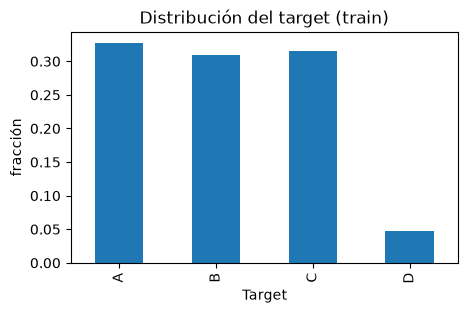

In [3]:
balance = y_tr.value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(5, 3))
balance.plot.bar(ax=ax, title="Distribución del target (train)")
ax.set_ylabel("fracción")
log_fig(fig, "target_balance")
balance.round(3).to_dict()

In [4]:
low_card = [c for c in cat_cols if X_tr[c].nunique() <= 10]
pd.concat({c: X_tr[c].value_counts(normalize=True, dropna=False).round(2) for c in low_card}, axis=1)

,F1,F2,F14,F16,F19
success,0.28,0.28,0.26,0.24,0.26
warning,0.25,0.25,0.27,0.24,0.24
unknown,0.24,0.25,0.23,0.24,0.27
error,0.22,0.21,0.23,0.25,0.21
NaN,0.01,0.01,0.01,0.01,0.01


## 3. Columnas planas (valor dominante)

Fracción del valor más frecuente entre los no nulos. Una columna donde casi todo es el mismo valor aporta poca información.

columnas planas: ['F24', 'F12', 'F3', 'F18', 'F21', 'F9', 'F6', 'F27']


,mean,std,min,max
F24,-0.26,2.56,-30.71,7.93
F12,0.04,1.75,-13.35,22.93
F3,-0.01,2.11,-18.44,14.87
F18,-0.02,2.38,-25.74,25.94
F21,-0.11,2.16,-20.93,14.54
F9,-0.17,2.99,-29.04,19.51
F6,-0.04,1.75,-12.02,16.67
F27,-0.04,1.95,-19.74,15.09


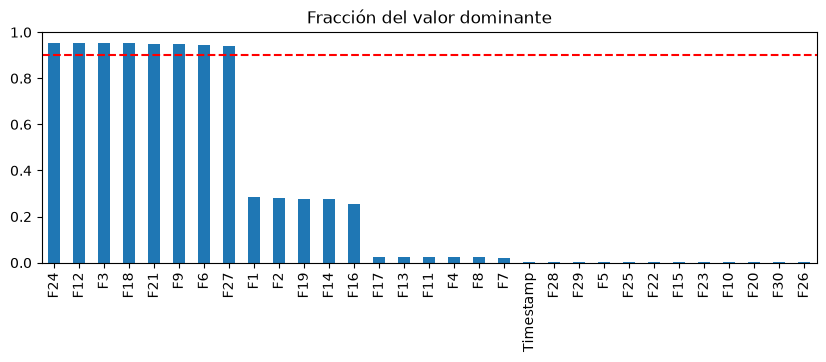

In [5]:
dominant = X_tr.apply(lambda s: s.value_counts(normalize=True).iloc[0]).sort_values(ascending=False)
FLAT_THRESHOLD = 0.9
flat_cols = dominant[dominant > FLAT_THRESHOLD].index.tolist()

fig, ax = plt.subplots(figsize=(10, 3))
dominant.plot.bar(ax=ax, title="Fracción del valor dominante")
ax.axhline(FLAT_THRESHOLD, color="red", ls="--")
log_fig(fig, "dominant_fraction")
print("columnas planas:", flat_cols)
X_tr[flat_cols].describe().T[["mean", "std", "min", "max"]].round(2)

## 4. Relación de cada feature con el target

**Numéricas**: mutual information (nulos imputados con la mediana, más un indicador de nulo para las columnas con muchos nulos). **Categóricas**: V de Cramér con corrección de sesgo, necesaria porque las de alta cardinalidad inflan la V sin corregir.

,MI,Cramér V
F22,0.757,NaN
F12,0.051,NaN
F18,0.048,NaN
F17,0.041,NaN
F25,0.032,NaN
F20,0.026,NaN
F6,0.026,NaN
F3,0.008,NaN
F13,NaN,0.137
F8,NaN,0.120


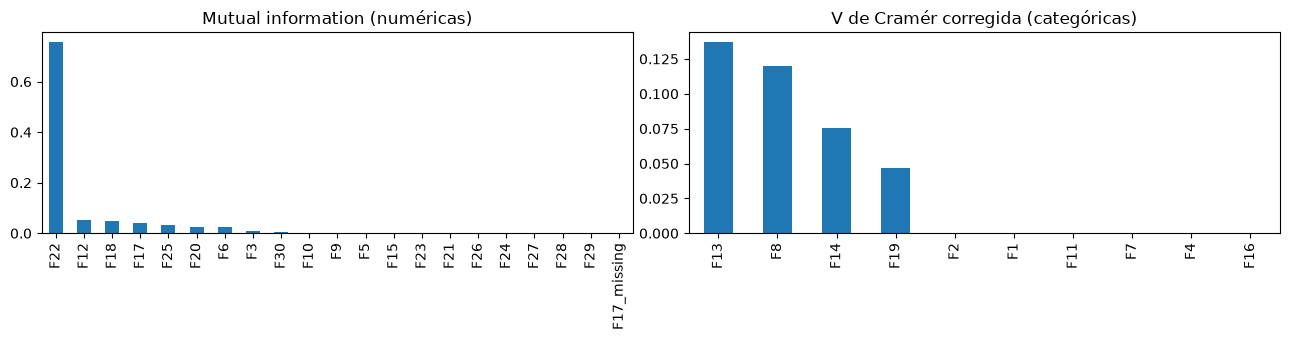

In [ ]:
high_null = quality.index[quality.null_frac > 0.5].tolist()
num_frame = X_tr[num_cols].fillna(X_tr[num_cols].median())
num_frame = num_frame.assign(**{f"{c}_missing": X_tr[c].isna().astype(int) for c in high_null})
mi = pd.Series(mutual_info_classif(num_frame, y_tr, random_state=settings.seed), index=num_frame.columns).sort_values(ascending=False)

# V = sqrt( (X²/n) / min(k-1, r-1) )
def cramers_v(x, target):
    table = pd.crosstab(x.fillna("NA"), target)
    chi2 = chi2_contingency(table)[0]
    n, (r, k) = table.values.sum(), table.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1)) # Correccicion bergsma
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_c - 1, r_c - 1))


cramer = pd.Series({c: cramers_v(X_tr[c], y_tr) for c in cat_cols}).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
mi.plot.bar(ax=axes[0], title="Mutual information (numéricas)")
cramer.plot.bar(ax=axes[1], title="V de Cramér corregida (categóricas)")
fig.tight_layout()
log_fig(fig, "target_relation")
log_table(mi.to_frame("mutual_info"), "mutual_info")
log_table(cramer.to_frame("cramers_v"), "cramers_v")
pd.concat([mi.head(8).rename("MI"), cramer.rename("Cramér V")], axis=1).round(3)

In [7]:
# F17: ¿informa la presencia del valor o el valor en sí?
pd.DataFrame({
    "frac_presente": X_tr["F17"].notna().groupby(y_tr).mean(),
    "media_si_presente": X_tr["F17"].groupby(y_tr).mean(),
}).round(2)

,frac_presente,media_si_presente
Target,,
A,0.10,35.15
B,0.13,-32.37
C,0.06,56.99
D,0.11,90.48


In [8]:
class_means = X_tr[num_cols].groupby(y_tr).mean().T
class_means.loc[mi.index.intersection(num_cols)[:8]].round(2)

Target,A,B,C,D
F22,9.63,18.85,30.86,40.43
F12,0.07,0.07,-0.07,0.37
F18,0.22,0.00,-0.29,0.00
F17,35.15,-32.37,56.99,90.48
F25,-0.15,0.14,0.08,-0.12
F20,-0.13,0.07,0.14,-0.08
F6,-0.03,-0.07,-0.03,0.00
F3,-0.12,0.27,-0.16,0.00


## 5. Correlación entre features numéricas

pares con |r| > 0.8: {('F5', 'F10'): 0.95, ('F5', 'F15'): 0.95, ('F5', 'F20'): 0.96, ('F5', 'F25'): 0.96, ('F5', 'F30'): 0.95, ('F10', 'F15'): 0.9, ('F10', 'F20'): 0.91, ('F10', 'F25'): 0.9, ('F10', 'F30'): 0.9, ('F15', 'F20'): 0.9, ('F15', 'F25'): 0.91, ('F15', 'F30'): 0.9, ('F20', 'F25'): 0.91, ('F20', 'F30'): 0.92, ('F25', 'F30'): 0.9}


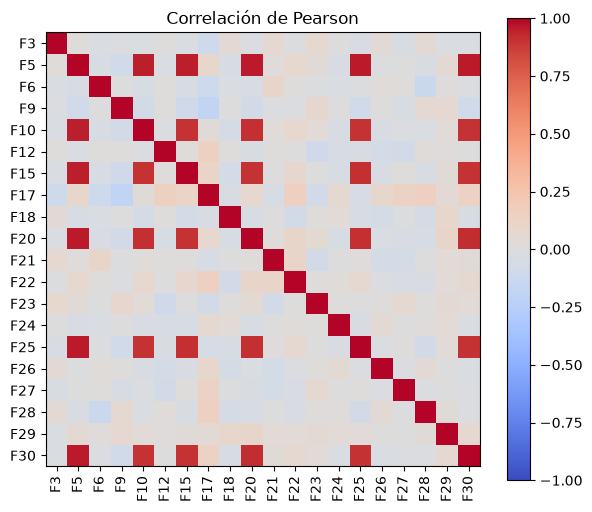

In [9]:
corr = X_tr[num_cols].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=90)
ax.set_yticks(range(len(num_cols)), num_cols)
fig.colorbar(im)
ax.set_title("Correlación de Pearson")
log_fig(fig, "correlation")
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("pares con |r| > 0.8:", pairs[pairs.abs() > 0.8].round(2).to_dict())

## 6. Cardinalidad de las categóricas

In [10]:
cardinality = pd.DataFrame({
    "n_unique": X_tr[cat_cols].nunique(),
    "top_freq": X_tr[cat_cols].apply(lambda s: s.value_counts(normalize=True).iloc[0]).round(3),
    "levels_lt_5": X_tr[cat_cols].apply(lambda s: (s.value_counts() < 5).sum()),
}).sort_values("n_unique", ascending=False)
log_table(cardinality, "cardinality")
cardinality

,n_unique,top_freq,levels_lt_5
F11,110,0.023,79
F13,109,0.023,80
F8,107,0.023,74
F7,107,0.020,71
F4,106,0.023,72
F1,4,0.286,0
F2,4,0.280,0
F14,4,0.275,0
F16,4,0.256,0
F19,4,0.276,0


## 7. Feature engineering de `Timestamp`

In [11]:
ts = pd.to_datetime(X_tr["Timestamp"], errors="coerce")
time_parts = pd.DataFrame({"month": ts.dt.month, "dayofweek": ts.dt.dayofweek, "hour": ts.dt.hour, "day": ts.dt.day})
time_cramer = pd.Series({c: cramers_v(time_parts[c].astype("Int64").astype(str), y_tr) for c in time_parts}).round(3)
log_table(time_cramer.to_frame("cramers_v"), "time_cramers_v")
print("timestamps nulos:", ts.isna().sum())
time_cramer.sort_values(ascending=False)

timestamps nulos: 5


month        0.954
day          0.098
hour         0.083
dayofweek    0.068
dtype: float64

pureza del mes respecto al target: 0.977


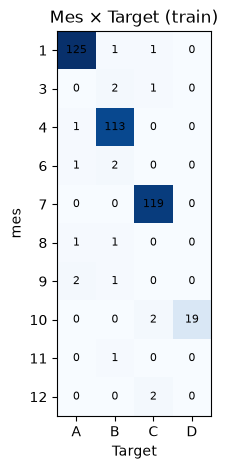

In [12]:
month_target = pd.crosstab(time_parts["month"], y_tr)
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(month_target, cmap="Blues")
ax.set_xticks(range(month_target.shape[1]), month_target.columns)
ax.set_yticks(range(month_target.shape[0]), month_target.index.astype(int))
for (i, j), v in np.ndenumerate(month_target.values):
    ax.text(j, i, v, ha="center", va="center", fontsize=8)
ax.set(xlabel="Target", ylabel="mes", title="Mes × Target (train)")
log_fig(fig, "month_vs_target")
purity = month_target.max(axis=1).sum() / month_target.values.sum()
print(f"pureza del mes respecto al target: {purity:.3f}")

### `F22` y las filas fuera de patrón

`F22` es la numérica con más información. Se comprueba si es solo un reflejo del mes o si sigue a la clase también cuando mes y clase no coinciden.

correlación F22 ~ mes: 0.83
filas fuera de patrón (mes no explica la clase): 24 (6.0%)


,mes,clase,F22
285,9.0,A,10.7
486,8.0,A,6.2
190,4.0,A,9.0
155,6.0,A,7.1
152,NaN,A,14.6
329,9.0,A,12.9
251,6.0,B,17.9
307,3.0,B,5.4
223,NaN,B,22.6
490,6.0,B,20.5


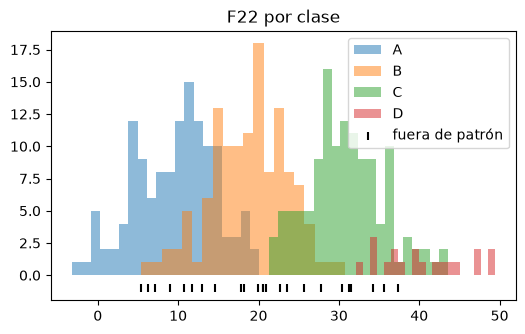

In [13]:
expected = time_parts["month"].map({1: "A", 4: "B", 7: "C", 10: "D"})
off_pattern = expected != y_tr
print(f"correlación F22 ~ mes: {X_tr['F22'].corr(time_parts['month']):.2f}")
print(f"filas fuera de patrón (mes no explica la clase): {off_pattern.sum()} ({off_pattern.mean():.1%})")

fig, ax = plt.subplots(figsize=(6, 3.5))
for label, group in X_tr["F22"].groupby(y_tr):
    ax.hist(group, bins=20, alpha=0.5, label=label)
ax.scatter(X_tr.loc[off_pattern, "F22"], np.full(off_pattern.sum(), -1), marker="|", color="k", label="fuera de patrón")
ax.legend()
ax.set_title("F22 por clase")
log_fig(fig, "f22_by_class")
pd.DataFrame({"mes": time_parts["month"], "clase": y_tr, "F22": X_tr["F22"].round(1)})[off_pattern].sort_values("clase")

## 8. Ablación rápida con los folds del proyecto

Regresión logística con el mismo preprocesado y los mismos folds, variando solo las features: sin mes, con mes (one-hot), solo mes y mes + `F22`.

,mean,std
sin_mes,0.672,0.050
con_mes,0.960,0.024
solo_mes,0.959,0.026
mes_F22,0.963,0.030


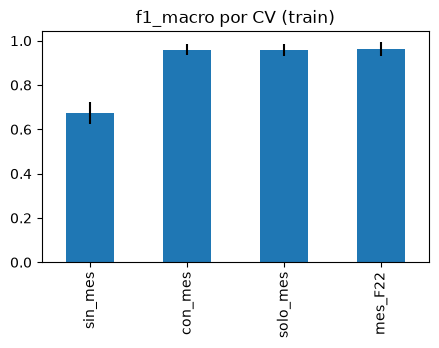

In [14]:
month = FunctionTransformer(lambda d: pd.to_datetime(d.iloc[:, 0], errors="coerce").dt.month.to_frame())
blocks = {
    "num": (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), [c for c in num_cols if c not in flat_cols]),
    "cat": (make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), low_card),
    "f22": (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), ["F22"]),
    "month": (make_pipeline(month, SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), ["Timestamp"]),
}
variants = {"sin_mes": ["num", "cat"], "con_mes": ["num", "cat", "month"], "solo_mes": ["month"], "mes_F22": ["month", "f22"]}

ablation = {}
for name, used in variants.items():
    prep = ColumnTransformer([(b, *blocks[b]) for b in used])
    model = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])
    scores = cross_val_score(model, X, y, cv=split.folds, scoring=settings.metric)
    ablation[name] = {"mean": scores.mean(), "std": scores.std()}
ablation = pd.DataFrame(ablation).T.round(3)
mlflow.log_metrics({f"ablation_{k}_{settings.metric}": v for k, v in ablation["mean"].items()})

fig, ax = plt.subplots(figsize=(5, 3))
ablation["mean"].plot.bar(ax=ax, yerr=ablation["std"], title=f"{settings.metric} por CV (train)")
log_fig(fig, "ablation")
ablation

## 9. Conclusiones

In [15]:
weak_categoricals = cramer[cramer < 0.1].index.tolist()
conclusions = {
    "drop_flat": flat_cols,
    "high_null": high_null,
    "weak_categoricals": weak_categoricals,
    "redundant_numeric": sorted({c for pair in pairs[pairs.abs() > 0.8].index for c in pair}),
    "strong_numeric": mi.index[mi > 0.1].tolist(),
    "time_feature": "month (one-hot)",
    "month_purity": round(float(purity), 3),
    "ablation": ablation["mean"].to_dict(),
}
mlflow.log_dict(conclusions, "conclusions.json")
mlflow.end_run()
conclusions

🏃 View run eda at: http://localhost:5000/#/experiments/4/runs/faadf069deb64a9893d27b4e1073f098
🧪 View experiment at: http://localhost:5000/#/experiments/4


{'drop_flat': ['F24', 'F12', 'F3', 'F18', 'F21', 'F9', 'F6', 'F27'],
 'high_null': ['F17'],
 'weak_categoricals': ['F14', 'F19', 'F2', 'F1', 'F11', 'F7', 'F4', 'F16'],
 'redundant_numeric': ['F10', 'F15', 'F20', 'F25', 'F30', 'F5'],
 'strong_numeric': ['F22'],
 'time_feature': 'month (one-hot)',
 'month_purity': 0.977,
 'ablation': {'sin_mes': 0.672,
  'con_mes': 0.96,
  'solo_mes': 0.959,
  'mes_F22': 0.963}}

### Decisiones para `features.py`

| # | Hallazgo | Evidencia | Decisión |
|---|---|---|---|
| 1 | El **mes** determina casi por completo el target | V de Cramér 0,95; pureza 0,977; ablación: solo mes 0,959 frente a 0,672 sin mes | `month` extraído de `Timestamp`, **one-hot** (sin orden entre meses). Timestamp nulo → categoría propia |
| 2 | `F22` es la única numérica con señal fuerte | MI 0,76; medias por clase 10 / 19 / 31 / 40 | Mantener |
| 3 | ≈6 % de filas fuera de patrón (mes ≠ clase) | 24 filas en train; `F22` sigue a la clase también en ellas | Es el techo práctico de un modelo solo con mes; los modelos no lineales pueden combinar mes × `F22` |
| 4 | 8 columnas planas (F3, F6, F9, F12, F18, F21, F24, F27) | >90 % del mismo valor (0) | Eliminar |
| 5 | Grupo redundante F5, F10, F15, F20, F25, F30 | \|r\| ≥ 0,9 entre ellas; MI ≤ 0,03 | Eliminar |
| 6 | `F17`: 90 % nulos | La presencia no informa (6-13 % por clase), el valor sí; MI 0,04 | Mantener con imputación por mediana + indicador de nulo; candidata a descarte |
| 7 | Categóricas sin señal | Baja cardinalidad: V ≈ 0. Alta cardinalidad (~107 niveles, mayoría con <5 apariciones): V 0,12-0,14, no fiable | Eliminar todas |
| 8 | Resto de numéricas (F23, F26, F28, F29) | MI ≤ 0,01 | Eliminar |
| 9 | Nulos dispersos (≈1 % por columna, 1-3 por fila) | 372 de 400 filas tienen algún nulo | Imputar; nunca eliminar filas |

**Conjunto propuesto**: `month` (one-hot), `F22`, `F17` (+ indicador de nulo).

Como el EDA solo usa train, la evaluación en test de la fase 3 confirma (o no) estas decisiones sin data snooping. La ablación sin mes queda como referencia de lo que aportan las features por sí solas.
